# Match event search: a walkthrough

From StatsBomb events to a question in plain English, on Bayer Leverkusen's 2023/24 Bundesliga season, following one
moment all the way through: Leverkusen's first goal of the season (Leverkusen 3-2 RB Leipzig, minute 23).

Run `python scripts/download_data.py` first. Each section links to its methodology note in `docs/methodology/`.

In [1]:
import json
import warnings

import matplotlib.pyplot as plt
import pandas as pd

from match_event_search.graph import describe, following, season_graph
from match_event_search.plotting import plot_moment, plot_routes
from match_event_search.query import search
from match_event_search.rule_parser import Vocabulary, parse_verbose
from match_event_search.similarity import summary

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 60)

## 1-3. Data, tags and the graph
`season_graph()` loads the 34 matches, tags every event with the nine tag families (stage 2), builds the NetworkX graph
(stage 3) and the similarity index (stage 9). The tags are a table next to the graph.

In [2]:
g = season_graph()
tags = g.graph["tags"]
describe(g)

{'nodes': {'event': 136803,
  'possession': 5453,
  'half': 68,
  'match': 34,
  'season': 1},
 'edges': {'contains': 142358,
  'next': 136735,
  'same_player': 134985,
  'similar': 23925}}

### One moment, tagged
Possessions 43 and 44 of Leverkusen-Leipzig: Werner's lost pass, Xhaka's regain, and Frimpong's goal 9 seconds later.
Each row is an event ("atom") with some of its tags.

In [3]:
match = tags[tags.match_id == 3895052]
werner = match.index[match.turnover & match.player.eq("Timo Werner") & match.minute.eq(22)][0]
goal = match.index[match.player.eq("Jeremie Frimpong") & match.action.eq("shot") & match.minute.eq(23)][0]
moment = match[match["index"].between(match.loc[werner, "index"], match.loc[goal, "index"])
               & match.action.ne("ball_receipt")]
moment[["minute", "second", "team", "player", "action", "third", "phase", "outcome",
        "progressive", "turnover", "regain", "since_regain"]]

,minute,second,team,player,action,third,phase,outcome,progressive,turnover,regain,since_regain
id,,,,,,,,,,,,
c61834d9-5728-4ca4-9182-e212654f4075,22,54,RB Leipzig,Timo Werner,pass,middle,progression,failure,False,True,False,14.952
6ae9d9f3-f9e1-4667-8c85-47165f96395c,22,54,Bayer Leverkusen,Odilon Kossonou,block,middle,mid_block,NaN,False,False,False,NaN
c72c5705-e0b0-4776-8901-91e7f9327b7b,22,55,Bayer Leverkusen,Granit Xhaka,ball_recovery,attacking,transition,success,False,False,True,0.000
6b1de13d-8ce9-4947-ba9d-07b0885adb51,22,55,Bayer Leverkusen,Granit Xhaka,carry,attacking,transition,NaN,False,False,False,0.000
a837b47e-4156-451f-bb9e-1f19ed594b7b,22,57,Bayer Leverkusen,Granit Xhaka,pass,attacking,transition,success,True,False,False,1.673
618b5a5e-4b17-48aa-a44c-ad769dfff864,22,58,Bayer Leverkusen,Victor Okoh Boniface,carry,attacking,transition,NaN,False,False,False,3.328
ae3b8e23-0618-4dae-b166-f0cc3f8c7657,22,59,RB Leipzig,Willi Orban,pressure,defensive,counterpress,NaN,False,False,False,NaN
5de4604e-56f3-471b-ac26-54bc80920a73,23,0,Bayer Leverkusen,Victor Okoh Boniface,miscontrol,attacking,transition,failure,False,False,False,4.725
9e54a35f-0f70-4af1-ab2b-ee2631f7c0d7,23,1,Bayer Leverkusen,Victor Okoh Boniface,ball_recovery,attacking,transition,success,False,False,False,6.382


### Walking the graph
From Werner's lost pass, follow the `next` edges for 12 seconds. Frimpong's goal comes 10.5 s after the turnover.

In [4]:
[(tags.loc[e, "player"], tags.loc[e, "action"], round(float(s), 1)) for e, s in following(g, werner, within_s=12)
 if tags.loc[e, "action"] != "ball_receipt"]

[('Odilon Kossonou', 'block', 0.1),
 ('Granit Xhaka', 'ball_recovery', 1.4),
 ('Granit Xhaka', 'carry', 1.4),
 ('Granit Xhaka', 'pass', 3.1),
 ('Victor Okoh Boniface', 'carry', 4.8),
 ('Willi Orban', 'pressure', 5.6),
 ('Victor Okoh Boniface', 'miscontrol', 6.2),
 ('Victor Okoh Boniface', 'ball_recovery', 7.8),
 ('Victor Okoh Boniface', 'carry', 7.8),
 ('Victor Okoh Boniface', 'pass', 9.8),
 ('Jeremie Frimpong', 'shot', 10.5),
 ('Janis Blaswich', 'goalkeeper', 10.8)]

## 4. A query in JSON
The format the parsers produce (stage 4): turnovers in Leverkusen's own half followed by an opponent shot within 10 s.

In [5]:
query = {"sequence": [
    {"filter": {"turnover": True, "our_team": True, "half": "own"}},
    {"filter": {"action": "shot"}, "team": "other", "within_s": 10},
]}
results = search(query, g)
print(len(results), "moments")
results.drop(columns=["match_id", "steps", "span"]).head()

18 moments


,match,period,minute,second,players,outcome,duration_s
0,2023-09-15 Bayern Munich 2-2 Bayer Leverkusen,1,2,50,"Granit Xhaka, Konrad Laimer",on_target,8.5
1,2023-10-21 Wolfsburg 1-2 Bayer Leverkusen,1,37,51,"Alejandro Grimaldo García, Yannick Gerhardt",blocked,3.8
2,2023-10-21 Wolfsburg 1-2 Bayer Leverkusen,1,38,38,"Exequiel Alejandro Palacios, Jonas Older Wind",blocked,6.7
3,2023-11-04 Hoffenheim 2-3 Bayer Leverkusen,1,11,41,"Edmond Fayçal Tapsoba, Marius Bülter",on_target,8.8
4,2023-11-25 Werder Bremen 0-3 Bayer Leverkusen,2,83,49,"Granit Xhaka, Justin Gideon Njinmah",off_target,5.8


## 5. A question in plain English
The rule-based parser (stage 5) turns the question into the same JSON. The LLM parser (stage 6) does the same with an
Anthropic model and your own API key; it is not run here.

In [6]:
vocab = Vocabulary.from_tags(tags)
parsed = parse_verbose("Regains in the final third that led to a goal", vocab)
print(json.dumps(parsed.query, indent=1))
goals = search(parsed.query, g)
goals.drop(columns=["match_id", "steps", "span"])

{
 "sequence": [
  {
   "filter": {
    "regain": true,
    "third": "attacking",
    "our_team": true
   }
  },
  {
   "filter": {
    "action": "shot",
    "outcome_detail": "goal"
   },
   "team": "same",
   "same_possession": true
  }
 ]
}


,match,period,minute,second,players,outcome,duration_s
0,2023-08-19 Bayer Leverkusen 3-2 RB Leipzig,1,22,55,"Granit Xhaka, Jeremie Frimpong",goal,9.1
1,2024-05-18 Bayer Leverkusen 2-1 Augsburg,1,11,12,"Amine Adli, Victor Okoh Boniface",goal,0.9


## 8. On the pitch
The first result, drawn from Leverkusen's side (attacking right); the steps of the question are numbered. In the app
the same plot can be stepped through event by event.

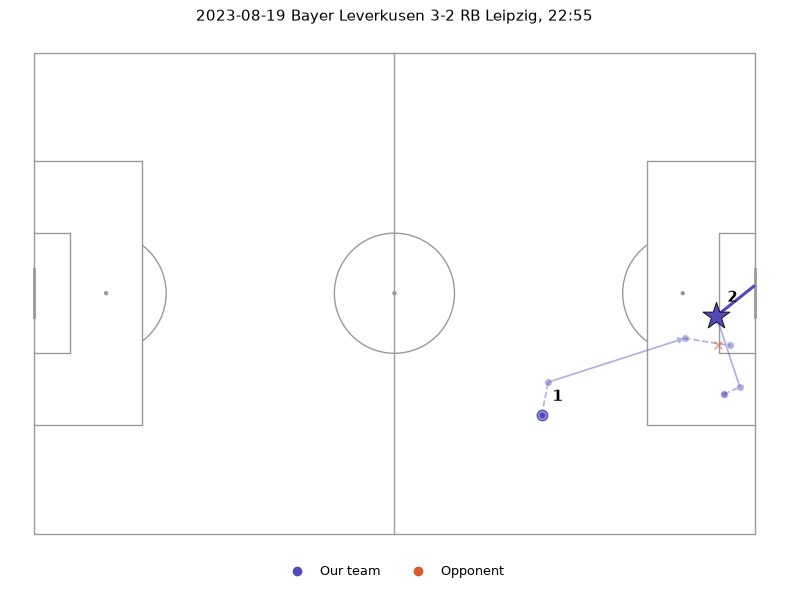

In [7]:
first = goals.iloc[0]
fig = plot_moment(tags.loc[first.span], list(first.steps), title=f"{first.match}, {first.minute}:{first.second:02d}")
plt.show()

## 9. Similar situations
The possessions across the season that looked most like the opening goal (route, tempo and how they started), and how
they ended. The outcome is not part of the comparison.

In [8]:
index = g.graph["similarity"]
neighbours = index.similar(3895052, 44, k=10)
print(summary(neighbours))
neighbours[["team", "minute", "second", "actions", "duration_s", "start", "shot", "goal", "distance"]]

10 similar possessions: 9 reached the box, 5 ended in a shot (0.74 xG), 0 in a goal, 3 in a lost ball


team  minute  second  actions  duration_s         start   shot   goal  distance
match_id possession                                                                                                
3895309  41             Bayer Leverkusen      28      31        7         9.8  Regular Play  False  False     0.084
3895194  71                     Augsburg      37       1        6         6.3  Regular Play   True  False     0.087
3895333  94          Eintracht Frankfurt      54       7       11        12.0  Regular Play  False  False     0.094
3895194  78             Bayer Leverkusen      41       3        8         8.3  Regular Play   True  False     0.097
         35             Bayer Leverkusen      17       2       10        13.8  Regular Play   True  False     0.098
3895309  125            Bayer Leverkusen      77      51        7         5.2  Regular Play  False  False     0.098
3895074  19                Bayern Munich       6       2        4         5.2  Regular Play  False  False     0.100
3895113  138                   Wolfsburg      73      11        7         7.4  Regular Play  False  False     0.106
3895333  113         Eintracht Frankfurt      68      50        6         4.7  Regular Play   True  False     0.110
3895210  35             Bayer Leverkusen      22      56        6         3.1  Regular Play   True  False     0.111

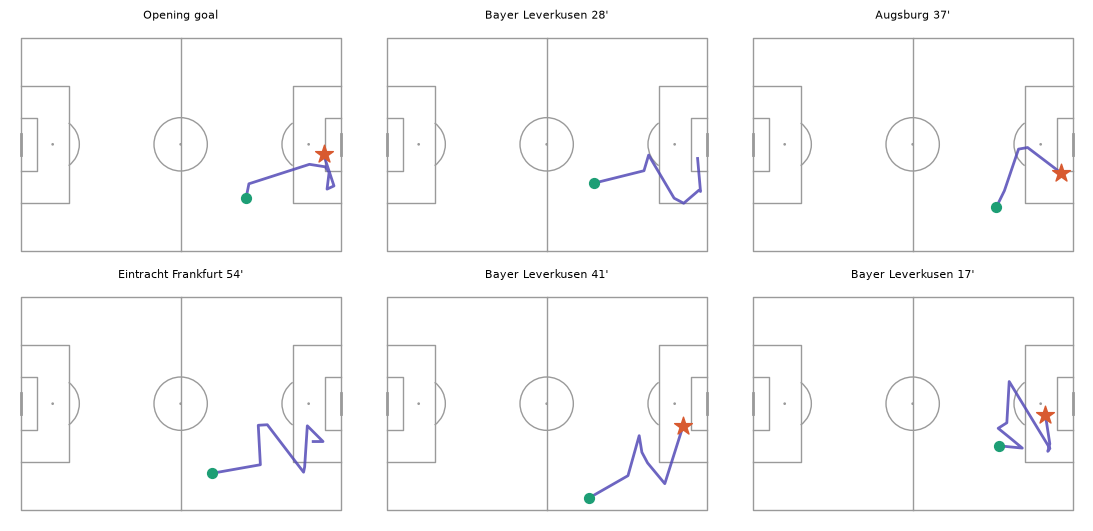

In [9]:
keys = [(3895052, 44)] + list(neighbours.index[:5])
fig = plot_routes([index.paths[k] for k in keys], ["Opening goal"] + [f"{index.table.loc[k].team} {index.table.loc[k].minute}'" for k in keys[1:]],
                  [bool(index.table.loc[k].shot) for k in keys])
plt.show()

## 7. Evaluation
31 questions with expected queries, scored by whether each parser's query finds exactly the same moments
(`python scripts/evaluate.py`, with `--llm` for the LLM parser).

In [10]:
pd.read_csv("../outputs/evaluation/summary.csv", index_col="parser")[["questions", "correct", "exact", "correct_pct"]]

,questions,correct,exact,correct_pct
parser,,,,
v1,31,19,17,61.3
v2,31,30,27,96.8
v2 + fallback,31,30,27,96.8
